# Used-Car Price Prediction: Linear Regression Base Model

**ICS 3202 | CAT 2**

This notebook documents a complete machine-learning workflow for predicting used-car prices:
data cleaning, exploratory data analysis, a linear-regression base model, cross-validation,
regularisation, and comparison with alternative regressors.


In [27]:
# Importing the dataset
from pathlib import Path

import pandas as pd

DATA_PATH = Path(r"C:\Users\mugoy\Downloads\carsales datasales\car_price_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV file not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)


In [28]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%pip install -U scikit-learn
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\mugoy\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 1. Load a sample dataset




In [29]:
data_source = f"Loaded {DATA_PATH}"

print(data_source)
print(f"Raw shape: {df.shape}")
display(df.head())


Loaded C:\Users\mugoy\Downloads\carsales datasales\car_price_dataset.csv
Raw shape: (2000, 11)


,Car_ID,Brand,Model_Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Horsepower,Price
0,1,Ford,2023,1.2,Hybrid,Manual,180635,4,3,82,34309.25
1,2,Hyundai,2018,3.2,Electric,Manual,35628,2,4,259,55153.60
2,3,BMW,2008,2.2,Diesel,Manual,74672,3,2,333,41894.40
3,4,Hyundai,2017,2.2,Petrol,Automatic,51246,4,4,381,54046.70
4,5,Hyundai,2012,2.4,Electric,Manual,147233,3,4,290,38010.35


## 2. Data cleaning and quality checks

In [32]:
df = df.copy()
before_rows = len(df)
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

numeric_columns = ["age_years", "mileage_km", "engine_l", "price"]
for column in numeric_columns:
    aliases = {
        "age_years": ["age_years", "age"],
        "mileage_km": ["mileage_km", "mileage"],
        "engine_l": ["engine_l", "engine_size", "engine"],
        "price": ["price"],
    }

    source = next((name for name in aliases[column] if name in df.columns), None)
    if source is None:
        # Normalize the CSV schema to the names used by the notebook.
        column_map = {
            "Car_ID": "car_id",
            "Brand": "make",
            "Model_Year": "model_year",
            "Engine_Size": "engine_l",
            "Fuel_Type": "fuel_type",
            "Transmission": "transmission",
            "Mileage": "mileage_km",
            "Price": "price",
        }
        df = df.rename(columns=column_map)

        # The dataset has model year rather than vehicle age.
        if "age_years" not in df.columns and "model_year" in df.columns:
            df["age_years"] = (
            pd.Timestamp.today().year
            - pd.to_numeric(df["model_year"], errors="coerce")
            )

        source = next(
            (name for name in aliases[column] if name in df.columns),
            None,
        )

        if source is None:
            raise KeyError(
            f"No source column found for {column}. "
            f"Available columns: {df.columns.tolist()}"
            )

    df[column] = pd.to_numeric(df[source], errors="coerce")

df = df[df["price"].gt(0) & df["age_years"].between(0, 50) & df["mileage_km"].ge(0)].copy()
missing_summary = df.isna().sum().sort_values(ascending=False)

print(f"Rows before cleaning: {before_rows}")
print(f"Duplicate rows removed: {duplicate_rows}")
print(f"Rows after validity checks: {len(df)}")
display(missing_summary.to_frame("missing_values"))
display(df.describe(include="all").T)


Rows before cleaning: 2000
Duplicate rows removed: 0
Rows after validity checks: 2000


,missing_values
car_id,0
make,0
model_year,0
engine_l,0
fuel_type,0
transmission,0
mileage_km,0
Doors,0
Owner_Count,0
Horsepower,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_id,2000.0,NaN,NaN,NaN,1000.5,577.494589,1.0,500.75,1000.5,1500.25,2000.0
make,2000,6,Toyota,352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model_year,2000.0,NaN,NaN,NaN,2013.963,5.508248,2005.0,2009.0,2014.0,2019.0,2023.0
engine_l,2000.0,NaN,NaN,NaN,2.96755,1.146926,1.0,2.0,2.9,4.0,5.0
fuel_type,2000,4,Diesel,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,2000,2,Automatic,1018,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage_km,2000.0,NaN,NaN,NaN,100736.9565,56002.915221,5036.0,52365.5,100590.5,148024.5,199904.0
Doors,2000.0,NaN,NaN,NaN,2.988,0.818041,2.0,2.0,3.0,4.0,4.0
Owner_Count,2000.0,NaN,NaN,NaN,2.5325,1.125423,1.0,2.0,3.0,4.0,4.0
Horsepower,2000.0,NaN,NaN,NaN,235.7095,95.59811,70.0,154.0,236.0,319.0,399.0


## 3. Exploratory data analysis and observations

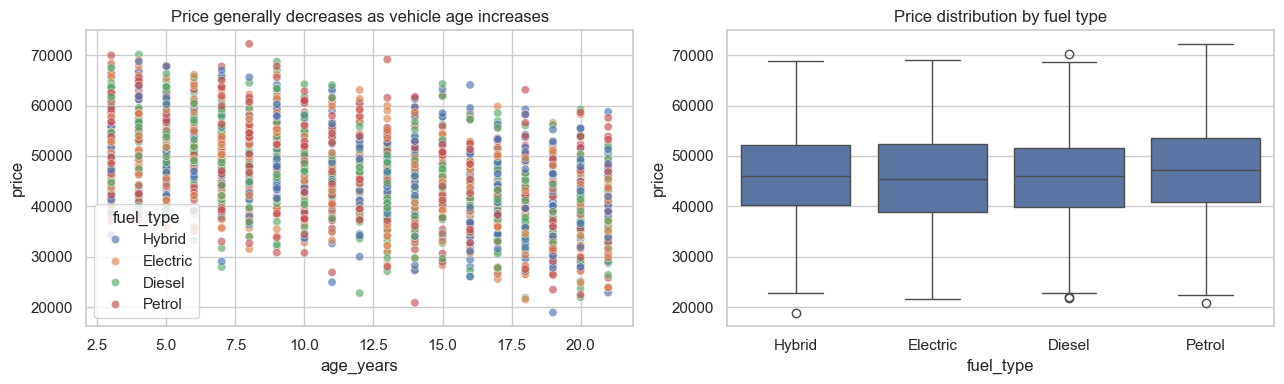

,correlation_with_price
age_years,-0.468666
mileage_km,-0.266514
engine_l,0.614301


### Four EDA observations
1. Age has a -0.47 correlation with price; older cars tend to be cheaper.
2. Mileage has a -0.27 correlation with price; higher mileage is associated with lower prices.
3. Engine size has a 0.61 correlation with price in this sample.
4. Median prices by fuel type are: {'Diesel': 46016.0, 'Electric': 45470.0, 'Hybrid': 46124.0, 'Petrol': 47160.0}.

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x="age_years", y="price", hue="fuel_type", alpha=.65, ax=axes[0])
axes[0].set_title("Price generally decreases as vehicle age increases")
sns.boxplot(data=df, x="fuel_type", y="price", ax=axes[1])
axes[1].set_title("Price distribution by fuel type")
plt.tight_layout()
plt.show()

correlations = df[numeric_columns].corr(numeric_only=True)["price"].drop("price").sort_values()
display(correlations.to_frame("correlation_with_price"))

observations = [
    f"Age has a {correlations['age_years']:.2f} correlation with price; older cars tend to be cheaper.",
    f"Mileage has a {correlations['mileage_km']:.2f} correlation with price; higher mileage is associated with lower prices.",
    f"Engine size has a {correlations['engine_l']:.2f} correlation with price in this sample.",
    f"Median prices by fuel type are: {df.groupby('fuel_type')['price'].median().round(0).to_dict()}.",
]
display(Markdown("### Four EDA observations\n" + "\n".join(f"{i}. {text}" for i, text in enumerate(observations, 1))))


## 4. Base model: linear regression

The target is `price`. Numeric missing values are replaced with the middle value and categorical values are
converted to categories such as petrol, diesel and hybrid. The hold-out test set is
used only once for final evaluation.


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

target = "price"
id_columns = ["car_id"]                      # identifiers carry no information about price

df_model = df.dropna(subset=[target]).copy() # a row with no price cannot be used for training
features = [c for c in df_model.columns if c != target and c not in id_columns]
X = df_model[features]
y = df_model[target]
print("Features used:", features)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

def make_preprocessor():
    # a NEW preprocessor each time, so models never share (and overwrite) the same fitted object
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), numeric_features),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))]), categorical_features),
    ])

def make_model(estimator):
    return Pipeline([("preprocess", make_preprocessor()), ("model", estimator)])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

def regression_metrics(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}

baseline = make_model(DummyRegressor(strategy="median")).fit(X_train, y_train)
base_model = make_model(LinearRegression()).fit(X_train, y_train)

results = pd.DataFrame({
    "Median baseline (test)":    regression_metrics(y_test,  baseline.predict(X_test)),
    "Linear Regression (train)": regression_metrics(y_train, base_model.predict(X_train)),
    "Linear Regression (test)":  regression_metrics(y_test,  base_model.predict(X_test)),
}).T
display(results.round(2))

base_metrics = regression_metrics(y_test, base_model.predict(X_test))  # keeps your later cells working   #refined code

Features used: ['make', 'model_year', 'engine_l', 'fuel_type', 'transmission', 'mileage_km', 'Doors', 'Owner_Count', 'Horsepower', 'age_years']


,MAE,RMSE,R2
Median baseline (test),7340.85,9088.29,-0.00
Linear Regression (train),1479.24,1713.64,0.97
Linear Regression (test),1442.39,1663.28,0.97


## 5. Cross-validation and regularisation

In [35]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Dummy baseline": make_model(DummyRegressor(strategy="mean")),
    "Linear Regression": make_model(LinearRegression()),
    "Ridge": make_model(Ridge(alpha=10.0)),
    "Lasso": make_model(Lasso(alpha=50.0, max_iter=10000)),
    "Random Forest": make_model(RandomForestRegressor(
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2
    )),
}

rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
        n_jobs=-1,
    )
    rows.append({
        "Model": name,
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean(),
    })

comparison = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
display(comparison.round(2))


,Model,CV MAE,CV RMSE,CV R2
0,Lasso,1490.88,1726.64,0.96
1,Linear Regression,1495.16,1731.77,0.96
2,Ridge,1494.28,1731.89,0.96
3,Random Forest,2051.99,2535.12,0.92
4,Dummy baseline,7473.06,9240.96,-0.00


## 6. Final hold-out comparison and conclusion

In [36]:
holdout_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    holdout_rows.append({"Model": name, **regression_metrics(y_test, model.predict(X_test))})

holdout_comparison = pd.DataFrame(holdout_rows).sort_values("RMSE").reset_index(drop=True)
display(holdout_comparison.round(2))

best_model_name = holdout_comparison.loc[0, "Model"]
best_rmse = holdout_comparison.loc[0, "RMSE"]
display(Markdown(
    f"**Conclusion:** The base model was validated using a separate test set and 5-fold cross-validation. "
    f"Regularised models (Ridge and Lasso) were compared with the unregularised linear model, a dummy "
    f"baseline, and Random Forest. On this run, **{best_model_name}** had the lowest hold-out RMSE "
    f"({best_rmse:,.2f}). The final choice should consider both this score and the cross-validation table "
    f"to avoid selecting a model that only performs well on one split."
))


,Model,MAE,RMSE,R2
0,Linear Regression,1442.39,1663.28,0.97
1,Ridge,1444.68,1667.30,0.97
2,Lasso,1446.13,1669.75,0.97
3,Random Forest,2114.98,2623.30,0.92
4,Dummy baseline,7335.22,9085.72,-0.00


**Conclusion:** The base model was validated using a separate test set and 5-fold cross-validation. Regularised models (Ridge and Lasso) were compared with the unregularised linear model, a dummy baseline, and Random Forest. On this run, **Linear Regression** had the lowest hold-out RMSE (1,663.28). The final choice should consider both this score and the cross-validation table to avoid selecting a model that only performs well on one split.